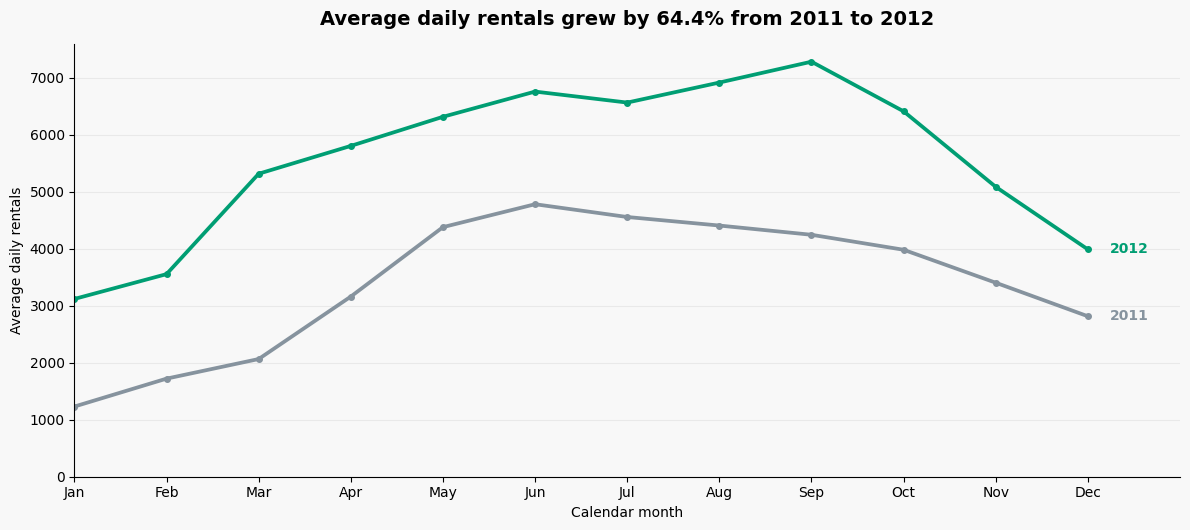

year,2011,2012,growth_pct
month,,,
1,1231.9,3120.8,153.3
2,1722.0,3556.4,106.5
3,2066.0,5318.5,157.4
4,3162.3,5807.5,83.6
5,4381.3,6318.2,44.2
6,4783.7,6761.0,41.3
7,4559.4,6568.0,44.1
8,4409.4,6919.5,56.9
9,4247.3,7285.8,71.5


2011 average daily rentals: 3,406
2012 average daily rentals: 5,600
Growth in mean daily rentals: 64.4%


In [1]:
# Confronto tra 2011 e 2012

# Importiamo le librerie e impostiamo i colori.
import pandas as pd
import matplotlib.pyplot as plt

import calendar
from pathlib import Path

MUTED = '#647280'
CLUSTER_0 = '#009E73'
NEUTRAL = '#86939E'
plt.rcParams['figure.facecolor'] = '#F8F8F8'
plt.rcParams['axes.facecolor'] = '#F8F8F8'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Apriamo i dati giornalieri e ricaviamo mese e anno.
day=pd.read_csv('../data/processed/bike_day_clean.csv')
day['dteday']=pd.to_datetime(day['dteday'])
day['year']=day['dteday'].dt.year
day['month']=day['dteday'].dt.month

# Calcoliamo i noleggi medi giornalieri nello stesso mese dei due anni.
monthly=day.groupby(['month','year'])['cnt'].mean().unstack().reindex(range(1,13))

# Calcoliamo la crescita percentuale della media giornaliera annuale.
annual=day.groupby('year')['cnt'].mean()
growth=(annual.loc[2012]/annual.loc[2011]-1)*100

# Disegniamo le due serie mensili, una per anno.
fig,ax=plt.subplots(figsize=(12,5.4))

# Scriviamo gli anni accanto alle linee per non usare una legenda separata.
for year,color in [(2011,NEUTRAL),(2012,CLUSTER_0)]:
    ax.plot(monthly.index,monthly[year],color=color,linewidth=2.7,marker='o',markersize=4)
    ax.text(12.24,monthly.loc[12,year],str(year),color=color,va='center',fontweight='bold')
ax.set_xlim(1,13)
ax.set_xticks(range(1,13),[calendar.month_abbr[i] for i in range(1,13)])
ax.set_ylim(bottom=0)
ax.set_ylabel('Average daily rentals')
ax.set_xlabel('Calendar month')
ax.grid(axis='y', alpha=0.2); ax.set_axisbelow(True)
ax.set_title(f'Average daily rentals grew by {growth:.1f}% from 2011 to 2012',
             fontsize=14,fontweight='bold',pad=14)

# Salviamo il grafico finale.
fig.tight_layout()
Path('../output/figures').mkdir(parents=True,exist_ok=True)
fig.savefig('../output/figures/RQ6_growth.png',dpi=200,bbox_inches='tight')
plt.show()

# Stampiamo la crescita dei singoli mesi e il totale annuale.
monthly['growth_pct']=(monthly[2012]/monthly[2011]-1)*100
display(monthly.round(1))
print(f'2011 average daily rentals: {annual.loc[2011]:,.0f}')
print(f'2012 average daily rentals: {annual.loc[2012]:,.0f}')
print(f'Growth in mean daily rentals: {growth:.1f}%')